In [ ]:
import gspread
from google.colab import auth
from google.auth import default
import pandas as pd

# 1. Authenticate your Google user account
auth.authenticate_user()

# 2. Authorize gspread with your credentials
creds, _ = default()
gc = gspread.authorize(creds)

# 3. Define your Google Sheet URL
sheet_url = 'https://docs.google.com/spreadsheets/d/1RE1opKGXKBzCGScz20erF0z7iMWQ0kLzkibOObnVDP4/edit?gid=617867683#gid=617867683'

# 4. Open the Google Sheet and fetch data
sh = gc.open_by_url(sheet_url)
worksheet = sh.get_worksheet(0) # Loads the first worksheet tab
data = worksheet.get_all_values()

# 5. Convert to pandas DataFrame using the first row as headers
df = pd.DataFrame(data[1:], columns=data[0])

# Display the first few rows of your DataFrame
df.head()

,Active Ingredient,Storage Temperature (°C),Warning Labels Present,Dissolution Rate (%),Disintegration Time (minutes),Impurity Level (%),Assay Purity (%),Safe/Not Safe
0,Aspirin,22.2,1,92.19,13.15,0.19,104.48,Safe
1,Aspirin,15.11,0,98.91,20.43,0.38,91.52,Not Safe
2,Paracetamol,29.74,1,89.23,17.94,0.15,99.98,Safe
3,Aspirin,21.91,1,96.12,17.35,0.41,93.25,Not Safe
4,Aspirin,23.2,0,90.54,16.87,0.28,100.51,Safe


In [ ]:
# Get both rows and columns at once
rows, cols = df.shape
print(f"Number of rows: {rows}")
print(f"Number of columns: {cols}")

Number of rows: 499
Number of columns: 8


In [ ]:
df.head()

,Active Ingredient,Storage Temperature (°C),Warning Labels Present,Dissolution Rate (%),Disintegration Time (minutes),Impurity Level (%),Assay Purity (%),Safe/Not Safe
0,Aspirin,22.2,1,92.19,13.15,0.19,104.48,Safe
1,Aspirin,15.11,0,98.91,20.43,0.38,91.52,Not Safe
2,Paracetamol,29.74,1,89.23,17.94,0.15,99.98,Safe
3,Aspirin,21.91,1,96.12,17.35,0.41,93.25,Not Safe
4,Aspirin,23.2,0,90.54,16.87,0.28,100.51,Safe


In [ ]:
import pandas as pd

# 1. Number of rows
print("=== 1. NUMBER OF ROWS ===")
print(len(df))
print()

# 2. Number of columns
print("=== 2. NUMBER OF COLUMNS ===")
print(len(df.columns))
print()

# 3. Column names
print("=== 3. COLUMN NAMES ===")
print(df.columns.tolist())
print()

# 4. Data types
print("=== 4. DATA TYPES ===")
print(df.dtypes)
print()

# 5. Summary statistics
print("=== 5. SUMMARY STATISTICS ===")
print(df.describe(include='all'))
print()

# 6. Unique values in categorical / object columns
print("=== 6. UNIQUE VALUES IN CATEGORICAL COLUMNS ===")
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

if len(categorical_cols) > 0:
    for col in categorical_cols:
        print(f"\nUnique values in '{col}':")
        print(df[col].unique())
else:
    print("No categorical/object columns found.")
print()

# 7. First 5 rows
print("=== 7. FIRST 5 ROWS ===")
df.head()

=== 1. NUMBER OF ROWS ===
499

=== 2. NUMBER OF COLUMNS ===
8

=== 3. COLUMN NAMES ===
['Active Ingredient', 'Storage Temperature (°C)', 'Warning Labels Present', 'Dissolution Rate (%)', 'Disintegration Time (minutes)', 'Impurity Level (%)', 'Assay Purity (%)', 'Safe/Not Safe']

=== 4. DATA TYPES ===
Active Ingredient                object
Storage Temperature (°C)         object
Warning Labels Present           object
Dissolution Rate (%)             object
Disintegration Time (minutes)    object
Impurity Level (%)               object
Assay Purity (%)                 object
Safe/Not Safe                    object
dtype: object

=== 5. SUMMARY STATISTICS ===
       Active Ingredient Storage Temperature (°C) Warning Labels Present  \
count                499                      499                    499   
unique                11                      317                      2   
top              Aspirin                    22.41                      0   
freq                  60     

,Active Ingredient,Storage Temperature (°C),Warning Labels Present,Dissolution Rate (%),Disintegration Time (minutes),Impurity Level (%),Assay Purity (%),Safe/Not Safe
0,Aspirin,22.2,1,92.19,13.15,0.19,104.48,Safe
1,Aspirin,15.11,0,98.91,20.43,0.38,91.52,Not Safe
2,Paracetamol,29.74,1,89.23,17.94,0.15,99.98,Safe
3,Aspirin,21.91,1,96.12,17.35,0.41,93.25,Not Safe
4,Aspirin,23.2,0,90.54,16.87,0.28,100.51,Safe


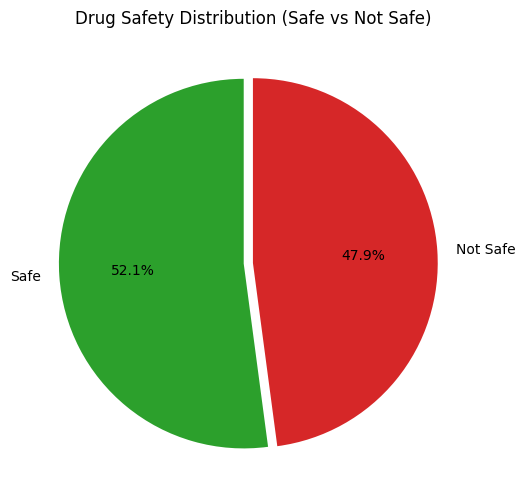

--------------------------------------------------
Number of Safe drugs: 260
Number of Not Safe drugs: 239
Total drugs analyzed: 499
Observation: Out of 499 total drug samples, 260 (52.1%) were classified as Safe, while 239 (47.9%) were classified as Not Safe.
--------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Count the occurrences of Safe and Not Safe
counts = df['Safe/Not Safe'].value_counts()
num_safe = counts.get('Safe', 0)
num_not_safe = counts.get('Not Safe', 0)

# 2. Plot the Pie Chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    colors=['#2ca02c', '#d62728'],
    startangle=90,
    explode=(0.05, 0)
)
plt.title('Drug Safety Distribution (Safe vs Not Safe)')
plt.show()

# 3. Observation Reporting Lines
print("-" * 50)
print(f"Number of Safe drugs: {num_safe}")
print(f"Number of Not Safe drugs: {num_not_safe}")
print(f"Total drugs analyzed: {len(df)}")
print(f"Observation: Out of {len(df)} total drug samples, {num_safe} ({num_safe/len(df)*100:.1f}%) were classified as Safe, while {num_not_safe} ({num_not_safe/len(df)*100:.1f}%) were classified as Not Safe.")
print("-" * 50)

=== ACTIVE INGREDIENT COUNTS ===
Total Unique Ingredients: 11

Active Ingredient
Aspirin          60
Cetirizine       55
Amoxicillin      49
Ciprofloxacin    49
Paracetamol      48
Ibuprofen        48
Metformin        45
Omeprazole       42
Lisinopril       41
Atorvastatin     39
Unknown          23
Name: count, dtype: int64


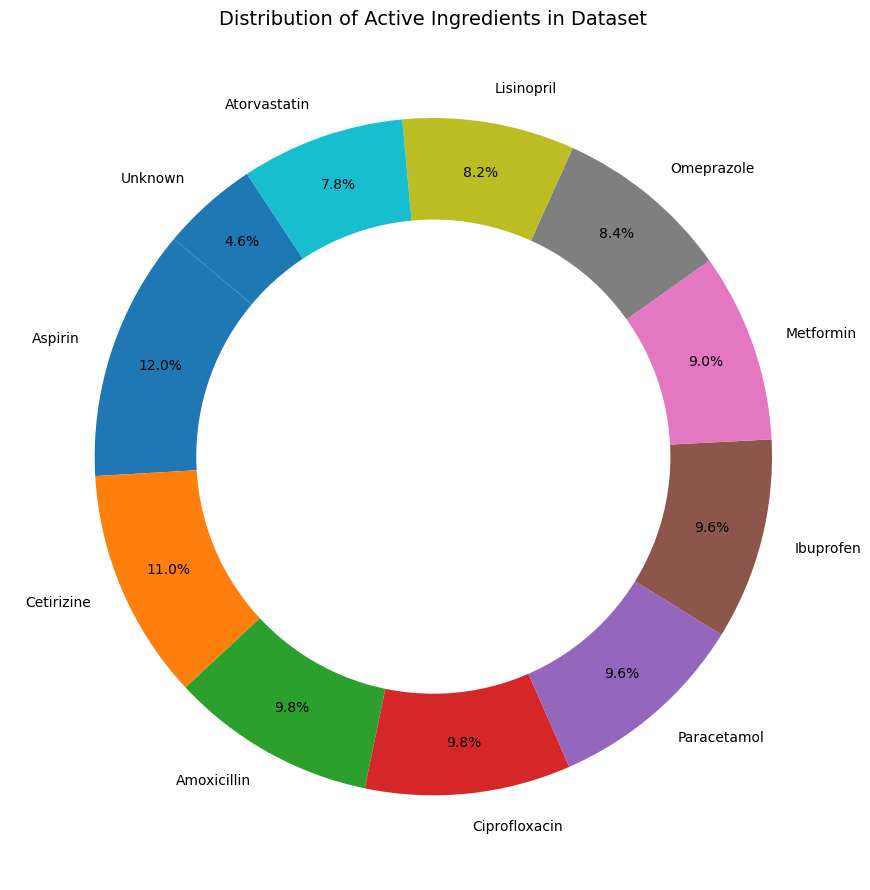

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Formula to count different types of Active Ingredients and their occurrences
ingredient_counts = df['Active Ingredient'].value_counts()

# Print the counts in text format
print("=== ACTIVE INGREDIENT COUNTS ===")
print(f"Total Unique Ingredients: {len(ingredient_counts)}\n")
print(ingredient_counts)

# 2. Create a Pie Chart
plt.figure(figsize=(9, 9))
plt.pie(
    ingredient_counts,
    labels=ingredient_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85
)

# Optional: Add a circle in the center to make it a clean donut pie chart
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Distribution of Active Ingredients in Dataset', fontsize=14)
plt.tight_layout()
plt.show()

=== DISSOLUTION RATE COMPARISON STATISTICS ===
Safe/Not Safe      Mean  Median   Min   Max  Std_Dev  Count
     Not Safe 88.847782   89.36 80.17 99.97 5.455848    239
         Safe 92.173731   91.41 85.04 99.93 4.351484    260

--------------------------------------------------



/tmp/ipykernel_8356/2064437131.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Safe/Not Safe', y='Dissolution Rate (%)', data=df, palette=['#2ca02c', '#d62728'])
/tmp/ipykernel_8356/2064437131.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Safe/Not Safe', y='Dissolution Rate (%)', data=df, palette=['#2ca02c', '#d62728'], capsize=0.1)


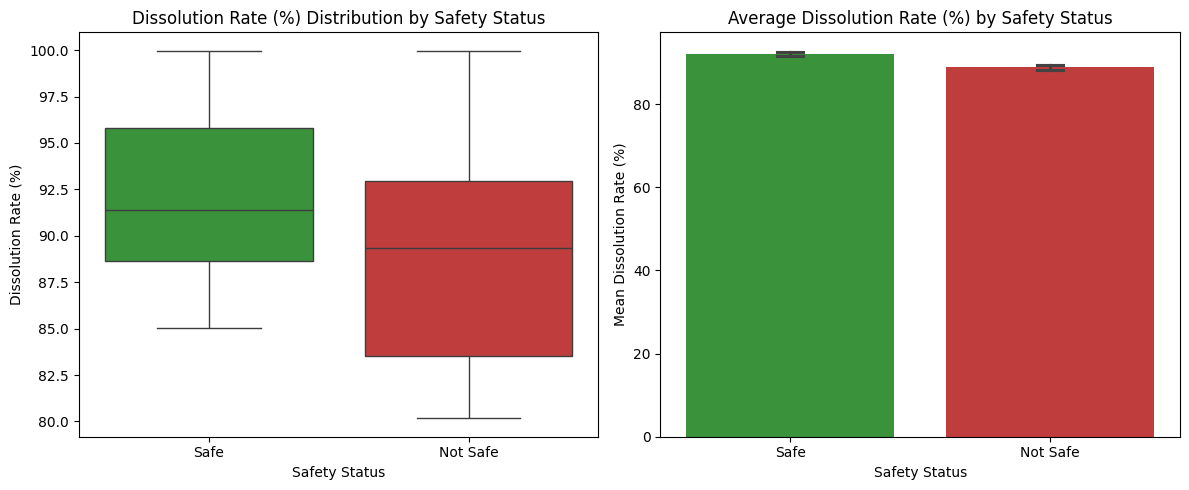

=== OBSERVATION REPORT ===
• Average Dissolution Rate for Safe drugs: 92.17%
• Average Dissolution Rate for Not Safe drugs: 88.85%
• Mean Difference: 3.33%


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean data: Convert 'Dissolution Rate (%)' to numeric values
df['Dissolution Rate (%)'] = pd.to_numeric(df['Dissolution Rate (%)'], errors='coerce')

# 2. Formula to compare QA metrics between Safe and Not Safe groups
dissolution_stats = df.groupby('Safe/Not Safe')['Dissolution Rate (%)'].agg(
    Mean='mean',
    Median='median',
    Min='min',
    Max='max',
    Std_Dev='std',
    Count='count'
).reset_index()

print("=== DISSOLUTION RATE COMPARISON STATISTICS ===")
print(dissolution_stats.to_string(index=False))
print("\n" + "-"*50 + "\n")

# 3. Data Representation 1: Boxplot (Shows distribution, median, and spread)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='Safe/Not Safe', y='Dissolution Rate (%)', data=df, palette=['#2ca02c', '#d62728'])
plt.title('Dissolution Rate (%) Distribution by Safety Status')
plt.xlabel('Safety Status')
plt.ylabel('Dissolution Rate (%)')

# Data Representation 2: Mean Bar Plot with Error Bars (Shows average comparison)
plt.subplot(1, 2, 2)
sns.barplot(x='Safe/Not Safe', y='Dissolution Rate (%)', data=df, palette=['#2ca02c', '#d62728'], capsize=0.1)
plt.title('Average Dissolution Rate (%) by Safety Status')
plt.xlabel('Safety Status')
plt.ylabel('Mean Dissolution Rate (%)')

plt.tight_layout()
plt.show()

# 4. Reporting Lines / Observations
mean_safe = df[df['Safe/Not Safe'] == 'Safe']['Dissolution Rate (%)'].mean()
mean_not_safe = df[df['Safe/Not Safe'] == 'Not Safe']['Dissolution Rate (%)'].mean()
diff = mean_safe - mean_not_safe

print("=== OBSERVATION REPORT ===")
print(f"• Average Dissolution Rate for Safe drugs: {mean_safe:.2f}%")
print(f"• Average Dissolution Rate for Not Safe drugs: {mean_not_safe:.2f}%")
print(f"• Mean Difference: {abs(diff):.2f}%")

=== DISINTEGRATION TIME COMPARISON STATISTICS ===
Safe/Not Safe      Mean  Median  Min   Max  Std_Dev  Count
     Not Safe 15.166025   14.81 1.05 29.98 8.114460    239
         Safe 14.490846   14.81 1.03 29.88 8.005927    260

--------------------------------------------------



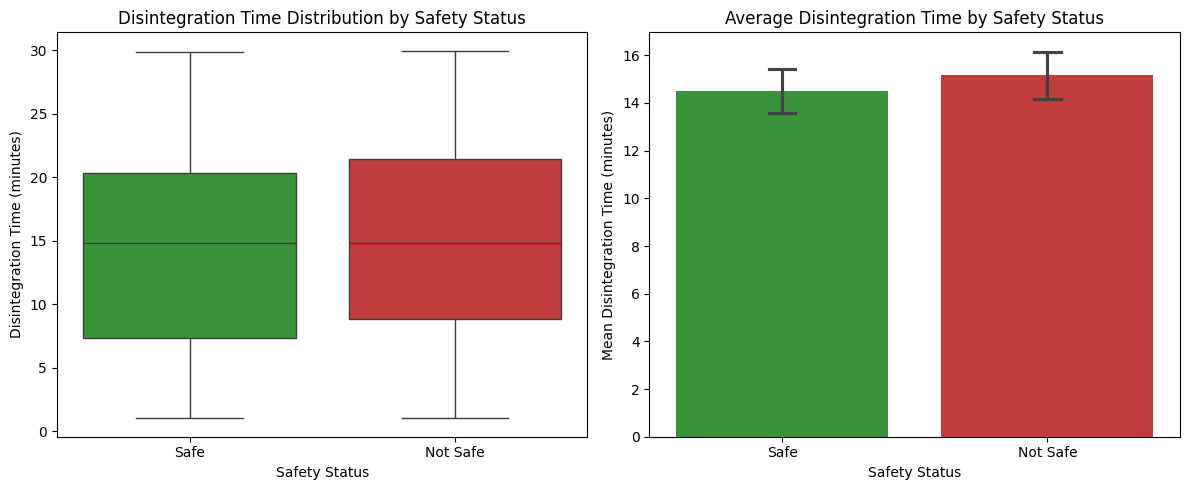

=== OBSERVATION REPORT ===
• Average Disintegration Time for Safe drugs: 14.49 minutes
• Average Disintegration Time for Not Safe drugs: 15.17 minutes
• Mean Difference: 0.68 minutes


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean data: Convert 'Disintegration Time (minutes)' to numeric values
df['Disintegration Time (minutes)'] = pd.to_numeric(df['Disintegration Time (minutes)'], errors='coerce')

# 2. Formula to compare QA metrics between Safe and Not Safe groups
disintegration_stats = df.groupby('Safe/Not Safe')['Disintegration Time (minutes)'].agg(
    Mean='mean',
    Median='median',
    Min='min',
    Max='max',
    Std_Dev='std',
    Count='count'
).reset_index()

print("=== DISINTEGRATION TIME COMPARISON STATISTICS ===")
print(disintegration_stats.to_string(index=False))
print("\n" + "-"*50 + "\n")

# 3. Visual Representation 1: Boxplot (Distribution & Outliers)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='Safe/Not Safe', y='Disintegration Time (minutes)', data=df, hue='Safe/Not Safe', palette=['#2ca02c', '#d62728'], legend=False)
plt.title('Disintegration Time Distribution by Safety Status')
plt.xlabel('Safety Status')
plt.ylabel('Disintegration Time (minutes)')

# Visual Representation 2: Mean Bar Plot with Error Bars
plt.subplot(1, 2, 2)
sns.barplot(x='Safe/Not Safe', y='Disintegration Time (minutes)', data=df, hue='Safe/Not Safe', palette=['#2ca02c', '#d62728'], capsize=0.1, legend=False)
plt.title('Average Disintegration Time by Safety Status')
plt.xlabel('Safety Status')
plt.ylabel('Mean Disintegration Time (minutes)')

plt.tight_layout()
plt.show()

# 4. Observation Reporting Lines
mean_safe = df[df['Safe/Not Safe'] == 'Safe']['Disintegration Time (minutes)'].mean()
mean_not_safe = df[df['Safe/Not Safe'] == 'Not Safe']['Disintegration Time (minutes)'].mean()
diff = mean_safe - mean_not_safe

print("=== OBSERVATION REPORT ===")
print(f"• Average Disintegration Time for Safe drugs: {mean_safe:.2f} minutes")
print(f"• Average Disintegration Time for Not Safe drugs: {mean_not_safe:.2f} minutes")
print(f"• Mean Difference: {abs(diff):.2f} minutes")

=== ASSAY PURITY COMPARISON STATISTICS ===
Safe/Not Safe       Mean  Median   Min    Max  Std_Dev  Count
     Not Safe  99.037741  98.400 90.22 109.90 6.059668    239
         Safe 100.042654 100.375 95.09 104.99 2.840815    260

--------------------------------------------------



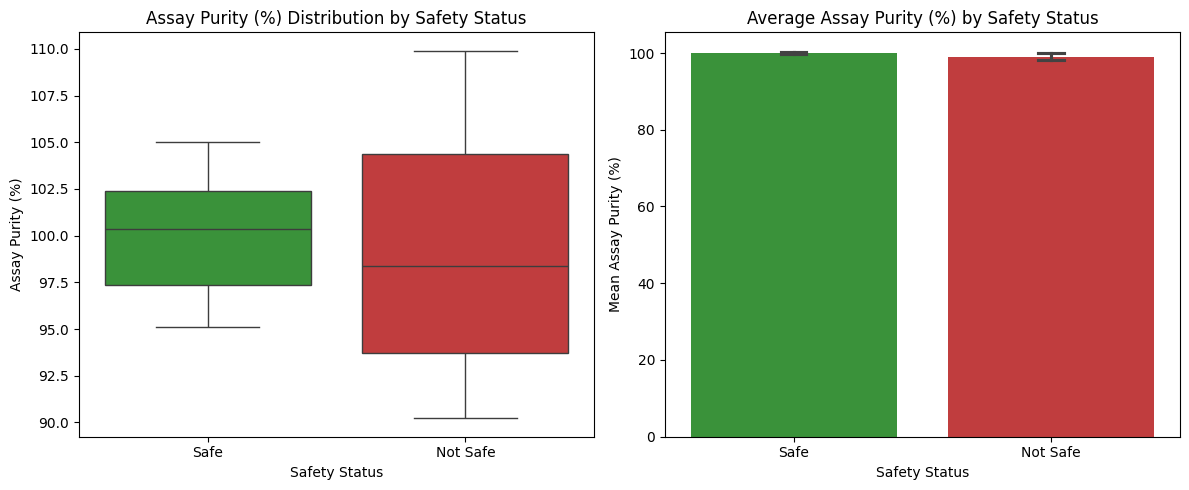

=== OBSERVATION REPORT ===
• Average Assay Purity for Safe drugs: 100.04%
• Average Assay Purity for Not Safe drugs: 99.04%
• Mean Difference: 1.00%


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean data: Convert 'Assay Purity (%)' to numeric values
df['Assay Purity (%)'] = pd.to_numeric(df['Assay Purity (%)'], errors='coerce')

# 2. Formula to compare QA metrics between Safe and Not Safe groups
purity_stats = df.groupby('Safe/Not Safe')['Assay Purity (%)'].agg(
    Mean='mean',
    Median='median',
    Min='min',
    Max='max',
    Std_Dev='std',
    Count='count'
).reset_index()

print("=== ASSAY PURITY COMPARISON STATISTICS ===")
print(purity_stats.to_string(index=False))
print("\n" + "-"*50 + "\n")

# 3. Visual Representation 1: Boxplot (Distribution & Outliers)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='Safe/Not Safe', y='Assay Purity (%)', data=df, hue='Safe/Not Safe', palette=['#2ca02c', '#d62728'], legend=False)
plt.title('Assay Purity (%) Distribution by Safety Status')
plt.xlabel('Safety Status')
plt.ylabel('Assay Purity (%)')

# Visual Representation 2: Mean Bar Plot with Error Bars
plt.subplot(1, 2, 2)
sns.barplot(x='Safe/Not Safe', y='Assay Purity (%)', data=df, hue='Safe/Not Safe', palette=['#2ca02c', '#d62728'], capsize=0.1, legend=False)
plt.title('Average Assay Purity (%) by Safety Status')
plt.xlabel('Safety Status')
plt.ylabel('Mean Assay Purity (%)')

plt.tight_layout()
plt.show()

# 4. Observation Reporting Lines
mean_safe = df[df['Safe/Not Safe'] == 'Safe']['Assay Purity (%)'].mean()
mean_not_safe = df[df['Safe/Not Safe'] == 'Not Safe']['Assay Purity (%)'].mean()
diff = mean_safe - mean_not_safe

print("=== OBSERVATION REPORT ===")
print(f"• Average Assay Purity for Safe drugs: {mean_safe:.2f}%")
print(f"• Average Assay Purity for Not Safe drugs: {mean_not_safe:.2f}%")
print(f"• Mean Difference: {abs(diff):.2f}%")

=== ASSAY PURITY COMPARISON STATISTICS ===
Safe/Not Safe       Mean  Median   Min    Max  Std_Dev  Count
     Not Safe  99.037741  98.400 90.22 109.90 6.059668    239
         Safe 100.042654 100.375 95.09 104.99 2.840815    260

--------------------------------------------------



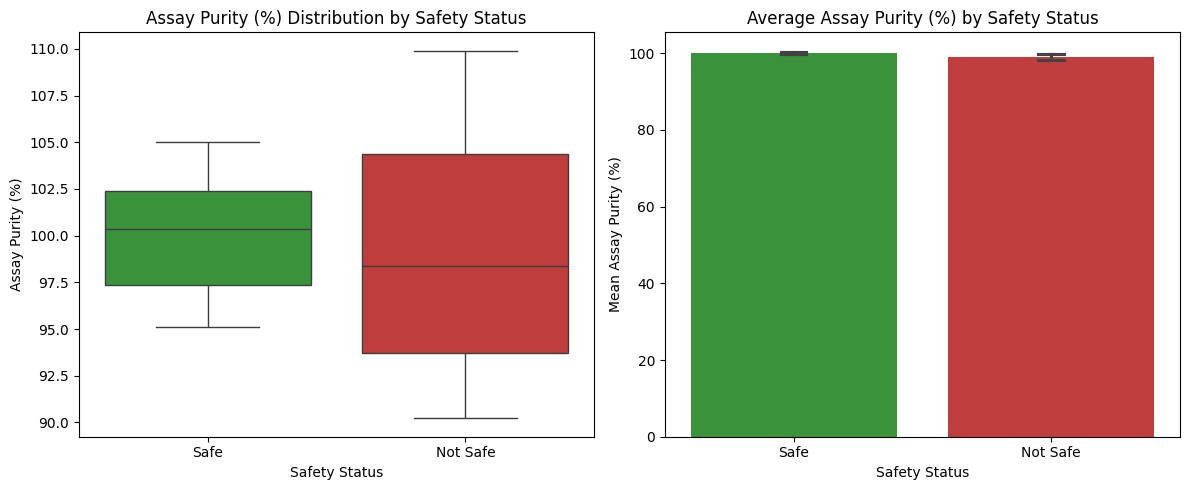

=== OBSERVATION REPORT ===
• Average Assay Purity for Safe drugs: 100.04%
• Average Assay Purity for Not Safe drugs: 99.04%
• Mean Difference: 1.00%


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean data: Convert 'Assay Purity (%)' to numeric values
df['Assay Purity (%)'] = pd.to_numeric(df['Assay Purity (%)'], errors='coerce')

# 2. Formula to compare QA metrics between Safe and Not Safe groups
assay_stats = df.groupby('Safe/Not Safe')['Assay Purity (%)'].agg(
    Mean='mean',
    Median='median',
    Min='min',
    Max='max',
    Std_Dev='std',
    Count='count'
).reset_index()

print("=== ASSAY PURITY COMPARISON STATISTICS ===")
print(assay_stats.to_string(index=False))
print("\n" + "-"*50 + "\n")

# 3. Visual Representation 1: Boxplot (Distribution & Outliers)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='Safe/Not Safe', y='Assay Purity (%)', data=df, hue='Safe/Not Safe', palette=['#2ca02c', '#d62728'], legend=False)
plt.title('Assay Purity (%) Distribution by Safety Status')
plt.xlabel('Safety Status')
plt.ylabel('Assay Purity (%)')

# Visual Representation 2: Mean Bar Plot with Error Bars
plt.subplot(1, 2, 2)
sns.barplot(x='Safe/Not Safe', y='Assay Purity (%)', data=df, hue='Safe/Not Safe', palette=['#2ca02c', '#d62728'], capsize=0.1, legend=False)
plt.title('Average Assay Purity (%) by Safety Status')
plt.xlabel('Safety Status')
plt.ylabel('Mean Assay Purity (%)')

plt.tight_layout()
plt.show()

# 4. Observation Reporting Lines
mean_safe = df[df['Safe/Not Safe'] == 'Safe']['Assay Purity (%)'].mean()
mean_not_safe = df[df['Safe/Not Safe'] == 'Not Safe']['Assay Purity (%)'].mean()
diff = mean_safe - mean_not_safe

print("=== OBSERVATION REPORT ===")
print(f"• Average Assay Purity for Safe drugs: {mean_safe:.2f}%")
print(f"• Average Assay Purity for Not Safe drugs: {mean_not_safe:.2f}%")
print(f"• Mean Difference: {abs(diff):.2f}%")